# Lithium from oilfield produced water by solvent extraction

For chemical engineers who know Python and some IDAES, but not lithium or solvent extraction. *Run All* takes about
2 minutes. The notebook follows the paper it accompanies, in six questions:

| Part | Question | Short answer |
|---|---|---|
| 1 | Why lithium from produced water? | Batteries need lithium, and this waste water holds some, but with about 115 sodium ions for every lithium ion. |
| 2 | How does solvent extraction work, and how is it modeled? | Water and an oil-like liquid are mixed and settled; the model calculates how much lithium and sodium end up in each liquid at every stage, inside an IDAES flowsheet. |
| 3 | Which solvent extracts best? | On softened MS-2, three systems recover about 99.7 % or more in three stages; only D2EHDTPA/BuPhen leaves more lithium than sodium in the loaded organic. |
| 4 | What does the whole process cost? | On Mars Hill, strip-liquor cleanup lowers counted cost relative to whole-water softening. Concentrator heat and BuPhen makeup are the largest costs of the strip-liquor design. |
| 5 | What margins did the nominal process attain? | Every attained operating margin is negative at the nominal carbonate price. |
| 6 | What can these predictions tell you, and what can't they? | They are reproduced model predictions, not measurements on these waters. |

An optional appendix optimizes a design and lets you try your own.

## 1. Why lithium from produced water?

**Answer:** produced water is a waste stream that holds lithium, and solvent extraction can take it out without
evaporation ponds, if the much larger amount of sodium can be kept out of the product.

- **Demand.** Batteries use about 88 % of the world's lithium, and lithium use rose about 20 % in 2025 (USGS Mineral
  Commodity Summaries 2026).
- **Today's sources.** Hard-rock ores, and continental brines concentrated in open-air evaporation ponds that lose most
  of the brine water.
- **Produced water.** Oil and gas wells bring up large volumes of salty water, managed as a waste. Some, such as the
  Smackover water of southern Arkansas, holds tens to a few hundred mg/L of lithium.
- **The difficulty.** The water holds far more sodium, calcium and magnesium than lithium:
  - calcium and magnesium consume acidic extractants and precipitate with carbonate, so they are removed first
    (**softening**) or tolerated by the extractant;
  - sodium, about **115 ions per lithium ion** in the main water here, competes for the extractant and follows lithium
    toward the product.

### Terms used throughout

| Term | Meaning |
|---|---|
| MS-2, Mars Hill | USGS produced-water samples from the Smackover Formation, Arkansas (168 and 423 mg/L Li) |
| softening | removing calcium and magnesium by precipitating them with sodium hydroxide and soda ash (Na$_2$CO$_3$) |
| O/A | organic-to-aqueous volume ratio |
| raffinate, loaded organic | the water leaving the last extraction stage; the organic carrying the extracted metals |
| $E_{Li}$, $D_M$, $\beta$ | lithium recovery; distribution coefficient of metal M (organic over aqueous concentration); separation factor $D_{Li}/D_{Na}$ |
| LCE | lithium carbonate equivalent: 1 kg of lithium makes 5.32 kg of Li$_2$CO$_3$ |
| break-even price | the lithium carbonate price at which the product just pays the operating cost |
| margin | value of the lithium carbonate minus the operating cost, per m$^3$ of raw water |

## 2. How does solvent extraction work, and how is it modeled?

**Answer:** the brine is mixed with an oil-like organic liquid that holds an extractant, and the two liquids settle
apart. Lithium, and some sodium, move into the organic. The model calculates how much lithium and sodium end up in each
liquid at every stage, inside an IDAES flowsheet.

### 2.1 Import the tools

IDAES and PrOMMiS pieces, the stage property packages, and small helpers that take the model `m` and do one job each.

In [1]:
import lithium_tutorial_tools as tools
import lithium_produced_water_tools as pw
import lithium_solvent_comparison_tools as sc

from idaes.core import FlowDirection, FlowsheetBlock
from idaes.core.util.model_statistics import degrees_of_freedom
from prommis.solvent_extraction.solvent_extraction import SolventExtraction
from pyomo.environ import ConcreteModel, value

from prommis.lithium_extraction.extraction.stage import (
    ExtentReactions,
    MolarFlowParameters,
)

tools.versions()

,version
ePC-SAFT Engine,1.3.1
IDAES,2.13.0
PrOMMiS,1.1.0
Pyomo,6.10.1


### 2.2 How a countercurrent cascade works

- Mix the water (the **aqueous** phase) with an oil-like **organic** phase that holds an extractant; lithium moves into
  the organic; the two liquids settle apart. One mix-and-settle step is a **stage**.
- **Countercurrent:** water flows from stage 1 to stage $N$, fresh organic enters at stage $N$ and flows back, so the
  water meets the cleanest organic just before it leaves.
- Afterwards, a dilute acid **scrub** washes sodium off the loaded organic, a stronger acid **strip** returns the
  lithium to a small volume of water, and the organic is reused.

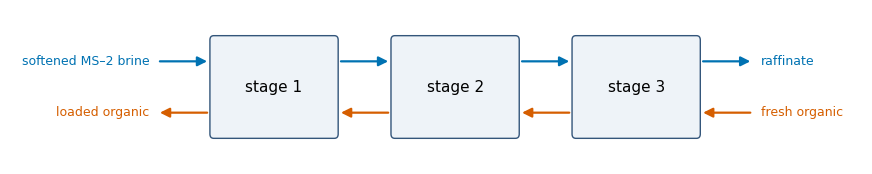

In [2]:
sc.draw_cascade()

**Why ePC-SAFT.** The brine is concentrated salt water (2.8 to 4.6 mol/L sodium in the feeds here), far from ideal, and
its acidity and sodium change from stage to stage. A fixed distribution coefficient cannot predict that. Electrolyte
PC-SAFT (**ePC-SAFT**), an equation of state for electrolyte solutions, gives the activity of every ion and molecule in
both liquids. Its equilibrium library, the **Engine**, solves each stage as a chemical and phase equilibrium.

The rest of this part builds the three-stage cascade above for the simplest system, **acid-form HBTA/TOPO** (HBTA,
benzoyltrifluoroacetone, the acidic extractant; TOPO, tri-*n*-octylphosphine oxide, a neutral co-extractant), at
25 °C and 1 atm.

### 2.3 The feed

MS-2 with calcium, magnesium, strontium and barium assumed already removed and no lithium lost. The same feed serves all
four systems in Part 3; a dash marks a species a system's model leaves out.

In [3]:
sc.feed_table()

,mol per L feed,mg/L,"model feed, HBTA/TOPO and DES (mol/L)","model feed, D2EHDTPA/BuPhen (mol/L)"
Li,0.0242,168,0.0242,0.0242
Na,2.79,"64,100",2.79,2.79
K,0.0588,"2,300",—,—
water,55.5,—,55.5,55.5
H,1.7e-06,0.00171,1.7e-06,—
Cl,2.87,"101,794",2.81,2.81
Mg,0,0,—,—
Ca,0,0,—,—
Sr,0,0,—,—
Ba,0,0,—,—


### 2.4 The chemistry

With HBTA written HA and TOPO written T, lithium and sodium enter the organic by releasing a proton:

$$
\mathrm{M^+_{(aq)} + HA_{(org)} + T_{(org)} \;\rightleftharpoons\; MA{\cdot}T_{(org)} + H^+_{(aq)}},
\qquad \mathrm{M = Li,\ Na}
$$

Reaction $r$ is at equilibrium when $\sum_{p,i} \nu_{r,pi} \ln a_{pi} = \ln K_r$, with activities $a$ from ePC-SAFT
and $K_r$ fitted to published data. The cell returns the Engine's chemistry record, the organic reference state and
the feed in mol/L.

In [4]:
chemistry, reference, brine = sc.acid_hbta_topo()
tools.species(chemistry)

{'aqueous species': ['water',
  'lithium-cation',
  'sodium-cation',
  'hydrogen-cation',
  'chloride-anion'],
 'organic species': ['diluent',
  'hbta',
  'topo',
  'LiA·T complex',
  'NaA·T complex']}

### 2.5 Build the flowsheet

Flows are mol/h at 1 L/h of feed, so every flow equals mol per litre of feed. Each cell adds one piece.

1. A steady-state flowsheet with one property package per liquid.

In [5]:
m = ConcreteModel()
m.fs = FlowsheetBlock(dynamic=False)
m.fs.aqueous_properties = MolarFlowParameters(
    phase="aqueous", species=chemistry.supports[0]
)
m.fs.organic_properties = MolarFlowParameters(
    phase="organic", species=chemistry.supports[1]
)

2. Transfer extents: in stage $k$, $\mathbf n^{out}_k = \mathbf n^{in}_k + \mathbf N\,\boldsymbol\xi_k$ with
   $\mathbf C\,\mathbf N = \mathbf 0$, so no extent creates or destroys lithium, sodium, exchangeable H, BTA or TOPO.

In [6]:
m.fs.extents = ExtentReactions(stoichiometry=tools.extent_stoichiometry(chemistry))

3. One PrOMMiS `SolventExtraction` unit with three stages: water forward, organic backward. `m.fs.boundary[s]` is the
   feed of species $s$ and `m.fs.stage[k].outlet[s]` the amount leaving stage $k$.

In [7]:
m.fs.extraction = SolventExtraction(
    number_of_finite_elements=3,
    heterogeneous_reaction_package=m.fs.extents,
    aqueous_stream={
        "property_package": m.fs.aqueous_properties,
        "flow_direction": FlowDirection.forward,
    },
    organic_stream={
        "property_package": m.fs.organic_properties,
        "flow_direction": FlowDirection.backward,
    },
)
tools.label_streams(m)
degrees_of_freedom(m)

25

4. Equilibrium in every stage: the Engine returns the outlet amounts from the inlet amounts as a Pyomo
   `ExternalFunction` with exact first and second derivatives.

In [8]:
tools.add_stage_equilibrium(m, [chemistry] * 3)
degrees_of_freedom(m)

10

5. Fix the feed.

In [9]:
for species, amount in brine.items():
    m.fs.boundary[species].fix(amount)
degrees_of_freedom(m)

5

6. Fix the paper's acid-form design: O/A = 3 and 0.3 mol/L each of HBTA and TOPO, both at their upper bounds. The model
   is now square.

In [10]:
start, design = sc.design("acid_A")
sc.add_design(m, design, reference)
assert degrees_of_freedom(m) == 0

### 2.6 Initialize and solve

`sc.initialize` solves the stages one at a time with the Engine for a starting point; IPOPT then solves all three
together with exact second derivatives. `tools.solve` stops with an error unless the optimality conditions are met.

In [11]:
sc.initialize(m, brine)
tools.solve(m, "acid_hbta_topo")

IPOPT: optimal; largest optimality-condition residual 3e-14


### 2.7 Result: acid release limits the acid form

Recovery is $E_{Li} = 1 - n_{Li,\,raffinate} / n_{Li,\,feed}$. Amounts leaving each stage, mol per litre of feed:

In [12]:
recovery = 1 - value(m.fs.stage[3].outlet["lithium-cation"]) / brine["lithium-cation"]
print(f"Lithium recovery: {100 * recovery:.2f} %")
tools.stage_profile(
    m,
    [
        "lithium-cation",
        "sodium-cation",
        "hydrogen-cation",
        "LiA·T complex",
        "NaA·T complex",
    ],
)

Lithium recovery: 39.71 %


stage,1,2,3
lithium-cation,0.02,0.0174,0.0146
sodium-cation,2.78,2.77,2.76
hydrogen-cation,0.0147,0.0239,0.0384
LiA·T complex,0.00961,0.00536,0.00286
NaA·T complex,0.0288,0.0183,0.0116


- Only about **40 %** of the lithium is recovered.
- Every Li⁺ extracted releases an H⁺, and the acid building up in the water holds extraction back.

## 3. Which solvent extracts best?

**Answer:** the three systems that release sodium instead of acid, or take up chloride, recover nearly all the lithium
in three stages. Only **D2EHDTPA/BuPhen** leaves more lithium than sodium in the loaded organic.

| System | How it takes up lithium |
|---|---|
| Acid-form HBTA/TOPO | trades a proton for Li⁺ (Part 2) |
| Sodium-saponified HBTA/TOPO | HBTA pre-reacted with NaOH, so it trades Na⁺ for Li⁺ instead of releasing acid |
| D2EHDTPA/BuPhen | a sodium-form dithiophosphate, bis(2-ethylhexyl)dithiophosphoric acid, trades Na⁺ for Li⁺; BuPhen (2,9-dibutyl-1,10-phenanthroline) binds the lithium |
| TBAC:DA/TOPO deep eutectic solvent (DES) | tetrabutylammonium chloride and decanoic acid with TOPO; takes up each metal ion with a chloride ion |

Each system runs at its own three-stage design for maximum lithium recovery, from the paper. Most optima sit on a design
bound:

In [13]:
sc.designs()

value
system                      design variable                                         
Acid HBTA/TOPO              O/A                                    3.0 (upper bound)
                            c, HBTA and TOPO each (mol/L organic)  0.3 (upper bound)
                            r_Na, sodium-form fraction of HBTA                     0
Sodium-saponified HBTA/TOPO O/A                                    3.0 (upper bound)
                            c, HBTA and TOPO each (mol/L organic)  0.4 (upper bound)
                            r_Na, sodium-form fraction of HBTA                 0.992
D2EHDTPA/BuPhen             O/A                                                 1.82
                            B, BuPhen (mol/L organic)              1.0 (upper bound)
                            S, sodium-form sites per mol feed Li   1.5 (upper bound)
TBAC:DA/TOPO DES            ammonia nitrogen (mol per L feed)                0.00512
                            TOPO mass fraction of the organic                  0.325

`sc.solve_all` builds and solves all four systems with the same stage structure. A design is kept only if IPOPT
converged, each stage re-solved on its own by the Engine matches the flowsheet, and every conserved total balances. The
first line confirms the hand-built model of Part 2 matches the study's own builder.

In [14]:
solved, status = sc.solve_all()
print(
    f"Largest outlet difference, hand-built against the study builder: {sc.largest_outlet_difference(m, solved):.1e} mol/L"
)
status

epcsaft_equilibrium prepared record 1


epcsaft_equilibrium prepared record 2


epcsaft_equilibrium prepared record 3


Largest outlet difference, hand-built against the study builder: 0.0e+00 mol/L


epcsaft_equilibrium prepared record 4


,solved,largest balance error (mol/L),largest stage re-solve difference (mol/L)
system,,,
Acid HBTA/TOPO,True,1.02e-14,1.42e-14
Sodium-saponified HBTA/TOPO,True,2.22e-16,2.13e-14
D2EHDTPA/BuPhen,True,2.52e-16,1.42e-14
TBAC:DA/TOPO DES,True,2.01e-14,7.82e-14


$E_{Li}$ is the lithium recovery of the whole three-stage cascade. $\beta$ and $x_{Na,org}$ (sodium's share of the lithium
plus sodium in the loaded organic) are for stage 1, where the water enters. $\Delta n_{Na,org}$ is the net sodium moved
into the organic (mol/m$^3$ of feed, negative when the saponified organic releases sodium), and the last row the lithium
left in the raffinate:

In [15]:
sc.headline(solved)

,Acid HBTA/TOPO,Sodium-saponified HBTA/TOPO,D2EHDTPA/BuPhen,TBAC:DA/TOPO DES
$E_{Li}$,0.397,> 0.999,0.997,$\approx 1$
$\beta = D_{Li}/D_{Na}$,46.4,163,753,370
"$x_{Na,org}$",0.75,0.979,0.336,0.9
"$\Delta n_{Na,org}$ (mol/m$^3$)",28.8,-88.3,-24.1,218
"$n_{Li,aq,N}$ (mol/L)",0.0146,8.63e-08,8.27e-05,$< 10^{-9}$


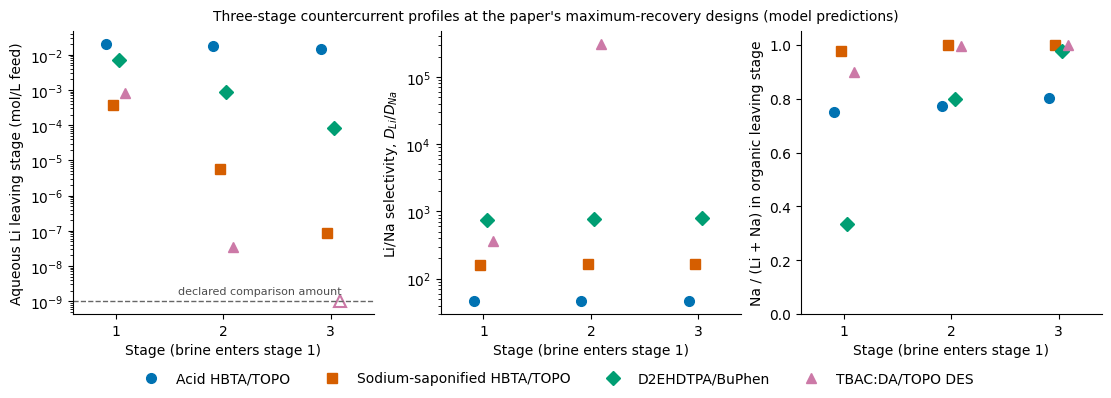

In [16]:
sc.plot_profiles(sc.profiles(solved))

- **Acid-form HBTA/TOPO is the outlier:** 39.7 % recovery against about 99.7 % or more for the other three.
- **High recovery is not a lithium-rich organic.** With about 115 Na per Li in the feed, sodium is **98 %** of the
  lithium plus sodium in the loaded organic for saponified HBTA/TOPO and **90 %** for the DES, but **34 %** for D2EHDTPA/BuPhen.
- That sodium follows lithium downstream, so the choice of process is decided after extraction: Part 4.

## 4. What does the whole process cost?

On Mars Hill, the strip-liquor route has the smallest deficit per cubic metre of raw water.
The same extractant system gives the lowest counted cost per tonne on USGS 45903.

![Block flow diagram of the process](lithium_produced_water_process_block_flow_diagram.png)

- **Whole-water softening (HBTA/TOPO).** Precipitate calcium and magnesium from the raw water with soda ash
  and sodium hydroxide. Extract lithium from the softened water, scrub sodium from the loaded organic, and strip
  lithium with hydrochloric acid. Recover unused strip acid and re-saponify the organic for reuse.
- **Strip-liquor cleanup (D2EHDTPA/BuPhen).** Extract lithium from the raw water and strip it with hydrochloric acid.
  Most feed hardness leaves in the raffinate. Remove the hardness that enters the strip liquor with sodium
  hydroxide and soda ash. Regenerate and recycle the stripped organic.
- **Both routes** concentrate the purified liquor before precipitating lithium carbonate with soda ash.
  Counted costs include reagents, solvent makeup, wet-sludge disposal and latent heat for modeled gross concentrator evaporation, assuming no heat recovery. Capital and labour are excluded.

### 4.1 Read the provisional designs

Use the retained `selections.json` and join to `designs.csv` by design ID and carbonate price.
The linked design records give the purchased amounts and item costs.
Recovery is the fraction of raw-water lithium that reaches solid lithium carbonate.
The costs and margins are model predictions. This walkthrough reads the archived results.

In [17]:
import json
from math import isclose

import pandas as pd
from IPython.display import Markdown, display

from prommis.lithium_extraction.process.priced_designs import (
    FITS,
    PRIMARY,
    RESULTS,
    REPRICE,
    SECONDARY,
    WATERS,
    load_matrix,
    selected_designs,
)

designs, selections = load_matrix()
retained = {
    (cell["water"], cell["fit"], cell["price"]): cell["design"]
    for cell in selected_designs(designs, selections)
    if cell["design"]
}
examples = [
    ("MarsHill", "fitted"),
    ("45903", "fitted"),
    ("MarsHill", "high"),
    ("MarsHill", "low"),
    ("Westmoreland", "fitted"),
    ("Westmoreland", "high"),
    ("Westmoreland", "low"),
]
primary = {case: retained[*case, PRIMARY] for case in examples}
records = {
    case: json.loads((RESULTS / row["record"]).read_text())
    for case, row in primary.items()
}


def design_name(case):
    water, fit = case
    name = f"USGS {water}" if water.isdecimal() else WATERS.get(water, water)
    return f"{name}, {FITS[fit]}"


hbta_prices = records["MarsHill", "high"]["rule"]["objective"]["ligand_prices_usd_kg"]
primary_price = float(primary["MarsHill", "fitted"]["price_usd_t_lce"])
display(
    Markdown(
        f"**Primary carbonate price:** {primary_price:,.0f} USD/t LCE (lithium carbonate equivalent). "
        f'HBTA makeup costs {hbta_prices["HBTA"]:.2f} USD/kg and TOPO is counted at '
        f'{hbta_prices["TOPO"]:g} USD/kg, so the HBTA/TOPO margins are ceilings.'
    )
)
pd.DataFrame(
    [
        {
            "Design": design_name(case),
            "Design ID": row["design_id"],
            "Stages": int(row["N"]),
            "Li recovery (%)": f'{float(row["recovery"]):.1%}'.removesuffix("%"),
            "LCE (kg/m³ raw)": f'{float(row["q_kg_lce_m3"]):.3f}',
            "Counted cost (USD/m³ raw)": f'{float(row["cost_usd_m3"]):,.2f}',
            "Counted cost (USD/t LCE)": f'{float(row["cost_usd_t_lce"]):,.0f}',
            "Margin (USD/m³ raw)": f'{float(row["margin_usd_m3"]):+.2f}',
        }
        for case, row in primary.items()
    ]
).set_index("Design")

**Primary carbonate price:** 9,000 USD/t LCE (lithium carbonate equivalent). HBTA makeup costs 11.48 USD/kg and TOPO is counted at 0 USD/kg, so the HBTA/TOPO margins are ceilings.

,Design ID,Stages,Li recovery (%),LCE (kg/m³ raw),Counted cost (USD/m³ raw),Counted cost (USD/t LCE),Margin (USD/m³ raw)
Design,,,,,,,
"Mars Hill, D2EHDTPA/BuPhen (Figiel)",535ff0f7b122130aa5b3,5,79.7,1.793,46.08,"25,693",-29.94
"USGS 45903, D2EHDTPA/BuPhen (Figiel)",e666a0d062c7acffd1cf,5,79.6,1.864,47.44,"25,446",-30.66
"Mars Hill, HBTA/TOPO (cascade fit)",b4cd121ca003456d8201,2,66.7,1.501,49.47,"32,966",-35.97
"Mars Hill, HBTA/TOPO (single-stage fit)",9561b3027599ed996cc5,2,64.1,1.444,50.35,"34,872",-37.35
"Westmoreland, D2EHDTPA/BuPhen (Figiel)",4d19daa35ea2f0e33411,5,80.2,0.499,26.05,"52,181",-21.56
"Westmoreland, HBTA/TOPO (cascade fit)",4fe41af914afb0a80ba6,1,72.1,0.449,17.78,"39,604",-13.74
"Westmoreland, HBTA/TOPO (single-stage fit)",7436b17b8be7ef63df79,4,73.6,0.458,20.22,"44,144",-16.10


### 4.2 Trace the counted cost to purchases

Multiply each purchase or disposal amount by its unit price and add the item costs. The Mars Hill strip-liquor
route spends most on concentrator heat and BuPhen makeup. The Mars Hill whole-water route spends most on soda ash for softening and
wet-sludge disposal. On Westmoreland, the HBTA/TOPO cascade fit spends most on HBTA makeup.

The evaporator duty uses gross water removed before any condensate return. For the same gross evaporation, three effects purchase the single-effect heat divided by their steam economy. Mechanical vapor recompression purchases electricity per cubic metre of condensate. Equipment choice and lithium-bearing mother-liquor return can change the selected operating conditions. Compare those options at matched controls before re-optimizing. The examples below use the retained single-effect process.


In [18]:
mars = records["MarsHill", "fitted"]
buphen_price = mars["rule"]["objective"]["ligand_prices_usd_kg"]["BuPhen"]
buphen_makeup = mars["priced"]["amount_kg_m3"]["BuPhen"]
buphen_cost = mars["priced"]["purchase_usd_m3"]["BuPhen"]
display(
    Markdown(
        f"Mars Hill BuPhen makeup of {buphen_makeup:.5f} kg/m³ of raw water at {buphen_price:.2f} USD/kg "
        f"adds **{buphen_cost:.2f} USD/m³**."
    )
)

items = {
    "BuPhen": "BuPhen makeup",
    "D2EHDTPA": "D2EHDTPA makeup",
    "HBTA": "HBTA makeup",
    "TOPO": "TOPO makeup",
    "diluent": "Diluent makeup",
    "octanol_dissolution": "Dissolved octanol makeup",
    "octanol_entrainment": "Entrained octanol makeup",
    "softening_Na2CO3": "Softening soda ash",
    "softening_NaOH": "Softening NaOH",
    "softening_HCl31": "Softening pH adjustment (HCl)",
    "scrub_HCl31": "Scrub acid",
    "strip_HCl31": "Strip acid",
    "cleanup_Na2CO3": "Strip-liquor cleanup soda ash",
    "cleanup_NaOH": "Strip-liquor cleanup NaOH",
    "regeneration_NaOH": "Regeneration NaOH",
    "saponification_NaOH": "Saponification NaOH",
    "neutralization_NaOH": "Neutralization NaOH",
    "carbonation_Na2CO3": "Carbonation soda ash",
    "sludge": "Wet-sludge disposal",
    "concentrator_heat": "Concentrator latent heat",
}
cost_examples = [("MarsHill", "fitted"), ("MarsHill", "high"), ("Westmoreland", "high")]
costs = pd.DataFrame(
    {
        design_name(case): records[case]["priced"]["purchase_usd_m3"]
        for case in cost_examples
    }
)
costs.reindex([item for item in items if item in costs.index]).rename(
    index=items
).rename_axis("Cost item (USD/m³ raw)").style.format("{:.2f}", na_rep="")

Mars Hill BuPhen makeup of 0.03646 kg/m³ of raw water at 569.02 USD/kg adds **20.75 USD/m³**.

,"Mars Hill, D2EHDTPA/BuPhen (Figiel)","Mars Hill, HBTA/TOPO (cascade fit)","Westmoreland, HBTA/TOPO (cascade fit)"
Cost item (USD/m³ raw),,,
BuPhen makeup,20.75,,
D2EHDTPA makeup,0.01,,
HBTA makeup,,1.30,8.58
TOPO makeup,,0.00,0.00
Diluent makeup,0.10,0.06,0.07
Dissolved octanol makeup,3.56,,
Entrained octanol makeup,0.06,,
Softening soda ash,,28.00,3.56
Softening NaOH,,2.11,0.21


### 4.3 Compare the carbonate price scenarios

If $q$ is the carbonate output in kg LCE per m³ of raw water, $P$ the carbonate price in USD/t LCE,
and $C$ the counted cost in USD per m³ of raw water, the margin and counted cost per tonne are

$$
M = \frac{Pq}{1000} - C,
qquad
C_{mathrm{t}} = \frac{1000 C}{q}.
$$

The counted cost per tonne is the carbonate price that would cover the counted items.
The middle-price scenario uses the controls selected at that price. HBTA/TOPO controls retain the original selection and are repriced for gross evaporation.
The highest-price scenario reprices
the primary designs with their controls, production and costs fixed.
Positive scenario margins show what remains to pay for excluded costs.

In [19]:
scenario_cases = [
    case for case in [*examples, ("BR2", "fitted")] if (*case, SECONDARY) in retained
]
scenarios = {
    (case, price): retained[*case, price]
    for case in scenario_cases
    for price in (PRIMARY, SECONDARY, REPRICE)
}
pd.DataFrame(
    {
        f'{float(scenarios[scenario_cases[0], price]["price_usd_t_lce"]):,.0f}': {
            design_name(case): f'{float(scenarios[case, price]["margin_usd_m3"]):+.2f}'
            for case in scenario_cases
        }
        for price in (PRIMARY, SECONDARY, REPRICE)
    }
).rename_axis("Margin (USD/m³ raw)").rename_axis(
    "Carbonate price (USD/t LCE)", axis="columns"
)

Carbonate price (USD/t LCE),"9,000","17,500","20,900"
Margin (USD/m³ raw),,,
"Mars Hill, D2EHDTPA/BuPhen (Figiel)",-29.94,-14.69,-8.59
"USGS 45903, D2EHDTPA/BuPhen (Figiel)",-30.66,-14.81,-8.47
"Westmoreland, HBTA/TOPO (cascade fit)",-13.74,-9.93,-8.40
"Westmoreland, HBTA/TOPO (single-stage fit)",-16.10,-12.21,-10.65
"BR-2, D2EHDTPA/BuPhen (Figiel)",-28.98,-19.84,-16.19


## 5. What margins did the nominal process attain?

The retained whole-process comparison uses the heat-priced operating margin per m³ of raw water.
Each row names the calibration, carbonate price, stage count, design ID and selection status.
Both saponified HBTA/TOPO fits use priced HBTA and zero-priced TOPO. D2EHDTPA/BuPhen uses the Figiel calibration and prices both ligands.
The 20,900 USD/t LCE rows reprice the same designs selected at 9,000 USD/t LCE.
Every design shown is provisional.
The margins are model predictions checked numerically. Operating costs include modeled concentrator latent heat at 5.97527 USD/GJ delivered.
Sensible heat, capital and labour are excluded.

Numbered waters are sample identifiers in the USGS Produced Waters Geochemical Database.

In [20]:
display(Markdown(pw.paper_screen_summary()))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(pw.paper_headline())

- At **9,000 USD/t LCE**, 36 of 36 attained margins are negative. The highest is **-13.74 USD/m³** for HBTA/TOPO (cascade fit) at Westmoreland.
- 6 water and calibration combinations have no verified target design.
- At **17,500 USD/t LCE**, no attained margin is positive.

,Water,Calibration,Price (USD/t LCE),N,Design ID,Li to carbonate (%),LCE (kg/m³),Margin (USD/m³),Status,Reason
0,Westmoreland,D2EHDTPA/BuPhen (Figiel),9000,5,4d19daa35ea2f0e33411,80.160,0.499201,-21.55605,provisional,
1,Westmoreland,D2EHDTPA/BuPhen (Figiel),20900,5,4d19daa35ea2f0e33411,80.160,0.499201,-15.61556,provisional,
2,Westmoreland,HBTA/TOPO (single-stage fit),9000,4,7436b17b8be7ef63df79,73.565,0.458131,-16.10060,provisional,
3,Westmoreland,HBTA/TOPO (single-stage fit),20900,4,7436b17b8be7ef63df79,73.565,0.458131,-10.64884,provisional,
4,Westmoreland,HBTA/TOPO (cascade fit),9000,1,4fe41af914afb0a80ba6,72.103,0.449026,-13.74203,provisional,
5,Westmoreland,HBTA/TOPO (cascade fit),20900,1,4fe41af914afb0a80ba6,72.103,0.449026,-8.39862,provisional,
6,1005,D2EHDTPA/BuPhen (Figiel),9000,5,dc08c41bddc40989293b,80.153,0.887399,-26.90405,provisional,
7,1005,D2EHDTPA/BuPhen (Figiel),20900,5,dc08c41bddc40989293b,80.153,0.887399,-16.34400,provisional,
8,1005,HBTA/TOPO (single-stage fit),9000,5,9f59cbbc22e581dbc377,65.623,0.726534,-52.37663,provisional,
9,1005,HBTA/TOPO (single-stage fit),20900,5,9f59cbbc22e581dbc377,65.623,0.726534,-43.73088,provisional,


## 6. What can these predictions tell you, and what can't they?

**Answer:** they rank solvents and waters on one consistent basis and show what drives cost. They are model
predictions with numerical checks. Sensible heat, capital and labour are excluded.

- **Model basis.** Each chemistry is fitted to published laboratory extraction data on other solutions.
- **Accuracy differs by system.** On published data withheld from the fits, saponified HBTA/TOPO predicts the lithium
  distribution coefficient within a factor of two at 10 of 11 points (average absolute relative deviation, AARD, 23 %);
  D2EHDTPA/BuPhen predicts 10 of 16 Li/Mg and Li/Ca selectivities within a factor of two (AARD 92 %), with most misses
  in calcium, and no withheld data test its Li/Na selectivity.
- **HBTA loss.** The saponified model underpredicts the one measured HBTA loss by 6–30 %. HBTA makeup is the largest
  counted cost for the Westmoreland cascade fit in Part 4.
- **Assumed inputs.** Scrub and strip fractions, softening doses, extractant prices and solvent losses are screening
  assumptions, not quotes or measurements.
- **Lower bounds.** With sensible heat, capital and labour excluded, break-even prices are lower bounds, and a positive margin does
  not establish profitability.

### Reproduction check

The four extraction systems are checked against the retained quantities and stage outlets. A point below the red
line is within tolerance. The Part 4 check reconciles the selected costs and margins within the retained numerical
error bounds. A failed check stops execution.

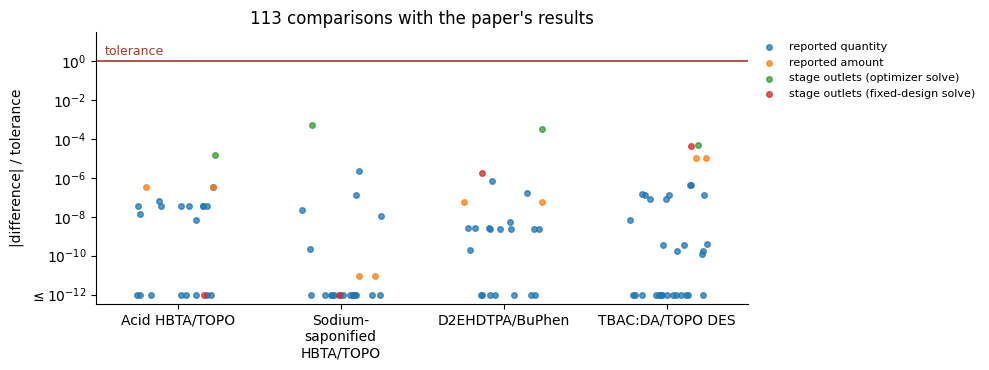

,comparisons,largest difference / tolerance,all within tolerance
Acid HBTA/TOPO,25,1.4e-05,✓
Sodium-saponified HBTA/TOPO,25,5.1e-04,✓
D2EHDTPA/BuPhen,25,3.1e-04,✓
TBAC:DA/TOPO DES,38,5.0e-05,✓


In [21]:
stage_summary, comparisons = sc.check_against_paper(solved)
stage_summary

In [22]:
for case, row in primary.items():
    priced = records[case]["priced"]
    assert isclose(
        sum(priced["purchase_usd_m3"].values()),
        float(row["cost_usd_m3"]),
        rel_tol=0,
        abs_tol=sum(priced["purchase_error_bounds_usd_m3"].values()),
    ), f"Cost items do not sum to counted cost for {design_name(case)}"
    assert (
        float(row["cost_usd_t_lce"]) == priced["cost_usd_t_lce"]
    ), f"Counted cost per tonne differs from the linked record for {design_name(case)}"

checked = {(case, PRIMARY): row for case, row in primary.items()} | scenarios
for (case, price), row in checked.items():
    calculated = price * float(row["q_kg_lce_m3"]) / 1000 - float(row["cost_usd_m3"])
    assert isclose(
        calculated,
        float(row["margin_usd_m3"]),
        rel_tol=0,
        abs_tol=float(row["margin_error_bound_usd_m3"]),
    ), f"Margin does not match carbonate revenue less counted cost for {design_name(case)} at {price:,} USD/t LCE"

print(
    f"{len(primary)} cost totals and {len(checked)} design-price margins agree within the retained numerical bounds."
)

7 cost totals and 18 design-price margins agree within the retained numerical bounds.


## Appendix: optimize and explore (optional)

### A.1 Optimize the acid-form design

Because the Engine is just one more equation to IDAES, the same flowsheet can be optimized. Start the acid-form cascade
of Part 2 at a weak design, O/A = 1 and $c$ = 0.1 mol/L:

In [23]:
design = m.fs.design
design.organic_to_aqueous_ratio.fix(1.0)
design.extractant_mol_l.fix(0.1)
sc.initialize(m, brine)
tools.solve(m, "acid_hbta_topo_start")
starting = {
    "O/A": 1.0,
    "c (mol/L organic)": 0.1,
    "$E_{Li}$": 1
    - value(m.fs.stage[3].outlet["lithium-cation"]) / brine["lithium-cation"],
}
starting

IPOPT: optimal; largest optimality-condition residual 3e-14


{'O/A': 1.0, 'c (mol/L organic)': 0.1, '$E_{Li}$': 0.08627474365531485}

Now free both inside the paper's bounds ($0.5 \le \mathrm{O/A} \le 3$, $0.05 \le c \le 0.30$ mol/L) and minimize the
lithium left in the raffinate:

In [24]:
from pyomo.environ import Objective

design.organic_to_aqueous_ratio.unfix()
design.extractant_mol_l.unfix()
m.feasibility.deactivate()
m.raffinate_lithium = Objective(expr=m.fs.stage[3].outlet["lithium-cation"])
print("Degrees of freedom:", degrees_of_freedom(m))
tools.solve(m, "acid_hbta_topo_optimize")

Degrees of freedom: 2


IPOPT: optimal; largest optimality-condition residual 9e-13


In [25]:
sc.optimum_table(m, brine, starting)

,starting design,optimized here,paper's optimum,relative difference
O/A,1,3,3,2.23e-10
c (mol/L organic),0.1,0.3,0.3,1.14e-10
$E_{Li}$,0.0863,0.397,0.397,1.85e-10


- Recovery rises from 8.6 % to 39.7 %.
- Both variables go to their upper bounds, matching the paper's optimum within $3 \times 10^{-10}$ relative difference.

### A.2 Try other stage designs

Pick a solvent system, the number of stages and its design, then run the cell below the widgets (a few seconds each).
Widgets work only in a running notebook (see the setup page beside this notebook).

In [26]:
designs = sc.DesignOptions()
designs

DesignOptions(children=(Dropdown(description='solvent system', layout=Layout(width='560px'), options=(('Acid H…

In [27]:
sc.run_design(designs)

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3.0 (upper bound), c = 0.3 (upper bound)",0.397,46.4,0.75,28.8,0.0146


Every design solved so far, recovery against the sodium share of the loaded organic. Two designs start the comparison:
the acid form at O/A = 2 and D2EHDTPA/BuPhen with one stage.

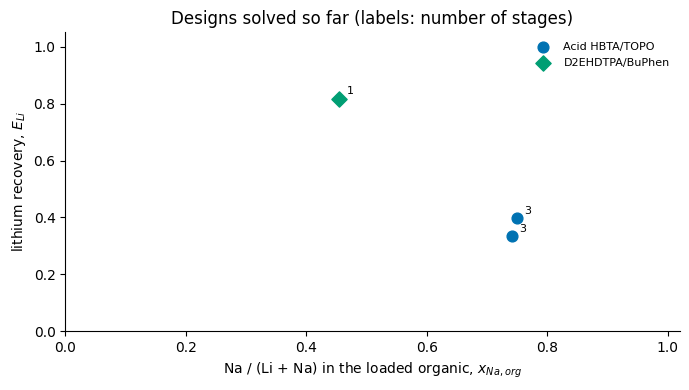

,system,stages,design,$E_{Li}$,$\beta = D_{Li}/D_{Na}$,"$x_{Na,org}$","$\Delta n_{Na,org}$ (mol/m$^3$)","$n_{Li,aq,N}$ (mol/L)"
0,Acid HBTA/TOPO,3,"O/A = 3.0 (upper bound), c = 0.3 (upper bound)",0.397,46.4,0.75,28.8,0.0146
1,Acid HBTA/TOPO,3,"O/A = 2, c = 0.3 (upper bound)",0.334,46.4,0.742,23.3,0.0161
2,D2EHDTPA/BuPhen,1,"O/A = 1.82, B = 1.0 (upper bound), S = 1.5 (up...",0.817,760,0.455,-19.8,0.00442


In [28]:
designs.system.label, designs.stages.value = "Acid HBTA/TOPO", 3
designs.sliders.children[0].value = 2.0
sc.run_design(designs)
designs.system.label, designs.stages.value = "D2EHDTPA/BuPhen", 1
sc.run_design(designs)
sc.compare_designs()